In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import torch.nn as nn
from torchvision import datasets,transforms
import torch

print(torch.cuda.is_available())
device=('cuda'if torch.cuda.is_available() else 'cpu')
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [3]:

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
train_transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomCrop(padding=8,size=32),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Normalize(mean,std)
])
eval_transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean,std)
])

In [6]:
!pip install -q datasets

In [4]:
from datasets import load_dataset

dataset = load_dataset("uoft-cs/cifar10")


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

50000
10000
2


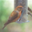

In [8]:
train_dataset = dataset["train"]
test_dataset = dataset["test"]

print(len(train_dataset))  # 50000
print(len(test_dataset))   # 10000

# Display one sample
sample = train_dataset[1002]
print(sample["label"])
display(sample["img"])

In [10]:
from torch.utils.data import Dataset, DataLoader
class CIFAR10Dataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        image = item["img"]  # PIL image
        label = item["label"]

        if self.transform:
            image = self.transform(image)

        return image, label

In [12]:
raw_train_dataset =CIFAR10Dataset(
   train_dataset,    transform=train_transform
)
raw_test_dataset=CIFAR10Dataset(
    
    test_dataset,
    transform=eval_transform,
    
)

In [13]:
import torch

print("Length of trainset =", len(dataset["train"]))

labels = torch.tensor(dataset["train"]["label"])
test_labels = torch.tensor(dataset["test"]["label"])

class_counts = torch.bincount(labels, minlength=10)

for digit, count in enumerate(class_counts):
    print(f"Class {digit}: {count.item()} images")

Length of trainset = 50000
Class 0: 5000 images
Class 1: 5000 images
Class 2: 5000 images
Class 3: 5000 images
Class 4: 5000 images
Class 5: 5000 images
Class 6: 5000 images
Class 7: 5000 images
Class 8: 5000 images
Class 9: 5000 images


In [13]:
test_class_counts = torch.bincount(test_labels, minlength=10)

print("\nTest set:")
for digit, count in enumerate(test_class_counts):
    print(f"Class {digit}: {count.item()} images")


Test set:
Class 0: 1000 images
Class 1: 1000 images
Class 2: 1000 images
Class 3: 1000 images
Class 4: 1000 images
Class 5: 1000 images
Class 6: 1000 images
Class 7: 1000 images
Class 8: 1000 images
Class 9: 1000 images


In [14]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
train_indices, val_indices = train_test_split(
    range(len(raw_train_dataset)),
    test_size=0.10,
    random_state=42,
    stratify=labels
)
x_train = Subset(raw_train_dataset, train_indices)
x_validation = Subset(raw_train_dataset, val_indices)
x_test=raw_test_dataset

In [16]:
train_loader=DataLoader(x_train,batch_size=64,shuffle=True,num_workers=2,
    pin_memory=True)
val_loader=DataLoader(x_validation,batch_size=64,shuffle=True,num_workers=2,
    pin_memory=True)
test_loader=DataLoader(x_test,batch_size=64,shuffle=True,num_workers=2,
    pin_memory=True)


In [28]:
class ImagCnn(nn.Module):
    def __init__(self,n_classes):
        super().__init__()
        self.feature=nn.Sequential(
            nn.Conv2d(in_channels=3,out_channels=16,kernel_size=3,padding=1,stride=1),
            nn.BatchNorm2d(16),
            nn.GELU(),
            nn.Conv2d(in_channels=16,out_channels=32,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=2,stride=2),
            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.Conv2d(in_channels=64,out_channels=64,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=2,stride=2),
            nn.Conv2d(in_channels=64,out_channels=128,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(128),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=2,stride=2)
            
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*4*4,128),
             nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(p=0.3),
            nn.Linear(128,64),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Linear(64,n_classes)
            
        )
    def forward(self,x):
            x=self.feature(x)
            return self.classifier(x)
            

In [30]:
model=ImagCnn(n_classes=10).to(device)
optimizer=torch.optim.AdamW(model.parameters(),lr=0.001)
loss_fn = nn.CrossEntropyLoss()

In [26]:
print("Model device:", next(model.parameters()).device)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

print("Images device:", images.device)
print("Labels device:", labels.device)

Model device: cuda:0
Images device: cuda:0
Labels device: cuda:0


In [37]:
class EarlyStoppingLoss:

    def __init__(self, patience=8, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta

        self.best_loss = None
        self.counter = 0
        self.best_state = None
        self.best_epoch = None

    def __call__(self, val_loss, model, epoch):

        improved = (
            self.best_loss is None or
            val_loss < self.best_loss - self.min_delta
        )

        if improved:
            self.best_loss = val_loss
            self.counter = 0
            self.best_epoch = epoch

            # Copie réelle des meilleurs poids en mémoire
            self.best_state = copy.deepcopy(
                model.state_dict()
            )

            # Sauvegarde aussi sur disque
            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": self.best_state,
                    "val_loss": self.best_loss
                },
                "best_cifar10_cnn.pt"
            )

            print(
                f"  Nouveau meilleur modèle "
                f"| val loss = {val_loss:.4f}"
            )

            return False

        self.counter += 1

        print(
            f"  Pas d'amélioration : "
            f"{self.counter}/{self.patience}"
        )

        return self.counter >= self.patience

In [44]:
import copy
def evaluate(model, loader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = loss_fn(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = logits.argmax(dim=1)

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

In [41]:
model = ImagCnn(n_classes=10).to(device)

loss_fn = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",      # val_loss doit diminuer
    factor=0.5,      # lr = lr × 0.5
    patience=3
)

early_stopping = EarlyStoppingLoss(
    patience=8,
    min_delta=0.001
)

epochs = 50

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "learning_rate": []
}

In [45]:
for epoch in range(1, epochs + 1):
    model.train()

    total_train_loss = 0.0
    total_train_correct = 0
    total_train_samples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = loss_fn(
            logits,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)

        total_train_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        total_train_correct += (
            predictions == labels
        ).sum().item()

        total_train_samples += batch_size

    train_loss = total_train_loss / total_train_samples

    train_accuracy = (
        total_train_correct / total_train_samples
    )

    # Validation après une epoch complète
    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    # Scheduler observe val_loss et réduit lr si nécessaire
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["learning_rate"].append(current_lr)

    print(
        f"Epoch {epoch:02d}/{epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.4f} | "
        f"val acc: {val_accuracy:.4f} | "
        f"lr: {current_lr:.6f}"
    )

    # Early stopping garde les meilleurs poids
    should_stop = early_stopping(
        val_loss,
        model,
        epoch
    )

    if should_stop:
        print("Early stopping déclenché.")
        break

Epoch 01/50 | train loss: 0.9409 | val loss: 0.9892 | train acc: 0.6702 | val acc: 0.6536 | lr: 0.001000
  Nouveau meilleur modèle | val loss = 0.9892
Epoch 02/50 | train loss: 0.8561 | val loss: 0.8520 | train acc: 0.6984 | val acc: 0.7002 | lr: 0.001000
  Nouveau meilleur modèle | val loss = 0.8520
Epoch 03/50 | train loss: 0.7881 | val loss: 0.7822 | train acc: 0.7242 | val acc: 0.7238 | lr: 0.001000
  Nouveau meilleur modèle | val loss = 0.7822
Epoch 04/50 | train loss: 0.7347 | val loss: 0.7400 | train acc: 0.7430 | val acc: 0.7412 | lr: 0.001000
  Nouveau meilleur modèle | val loss = 0.7400
Epoch 05/50 | train loss: 0.6935 | val loss: 0.6988 | train acc: 0.7596 | val acc: 0.7526 | lr: 0.001000
  Nouveau meilleur modèle | val loss = 0.6988
Epoch 06/50 | train loss: 0.6612 | val loss: 0.6597 | train acc: 0.7731 | val acc: 0.7676 | lr: 0.001000
  Nouveau meilleur modèle | val loss = 0.6597
Epoch 07/50 | train loss: 0.6309 | val loss: 0.6398 | train acc: 0.7815 | val acc: 0.7798 | lr

In [47]:
checkpoint = torch.load(
    "best_cifar10_cnn.pt",
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Epoch sauvegardée :", checkpoint["epoch"])
print("Meilleure val loss :", checkpoint["val_loss"])

Epoch sauvegardée : 46
Meilleure val loss : 0.40085945119857785


In [34]:
epochs=40
for epoch in range(epochs):
    model.train()
    train_loss=0
    for images,labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        logits=model(images)
        loss=loss_fn(logits,labels)
        loss.backward()
        optimizer.step()
        train_loss +=loss.item()
    print(f"for epoch:{epoch+1},loss was:{train_loss/len(train_loader)}")    

   

for epoch:1,loss was:0.442745842081918
for epoch:2,loss was:0.4421596815386279
for epoch:3,loss was:0.43543342543257907
for epoch:4,loss was:0.42074023917402054
for epoch:5,loss was:0.41595206153579056
for epoch:6,loss was:0.406627039171078
for epoch:7,loss was:0.40081600089218805
for epoch:8,loss was:0.398849033263766
for epoch:9,loss was:0.3925483149307018
for epoch:10,loss was:0.3864065794570541
for epoch:11,loss was:0.3825790889201347
for epoch:12,loss was:0.3771286251404407
for epoch:13,loss was:0.3729415530317717
for epoch:14,loss was:0.3655156068165194
for epoch:15,loss was:0.36144674506927416
for epoch:16,loss was:0.36408940897407854
for epoch:17,loss was:0.36021218793890014
for epoch:18,loss was:0.35265149184587324
for epoch:19,loss was:0.35369936675256625
for epoch:20,loss was:0.346583898475563
for epoch:21,loss was:0.3391013502206823
for epoch:22,loss was:0.3326666821958497
for epoch:23,loss was:0.3357185074657371
for epoch:24,loss was:0.3337984420676631
for epoch:25,loss wa

In [48]:
model.eval()
all_predictions = []
all_labels = []
with torch.no_grad():
  for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

In [49]:
from sklearn.metrics import classification_report
print('classification report ',classification_report(all_labels,all_predictions))

classification report                precision    recall  f1-score   support

           0       0.86      0.91      0.88      1000
           1       0.94      0.94      0.94      1000
           2       0.81      0.86      0.83      1000
           3       0.78      0.77      0.77      1000
           4       0.83      0.90      0.86      1000
           5       0.85      0.76      0.81      1000
           6       0.89      0.92      0.91      1000
           7       0.93      0.88      0.90      1000
           8       0.94      0.93      0.93      1000
           9       0.96      0.91      0.93      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



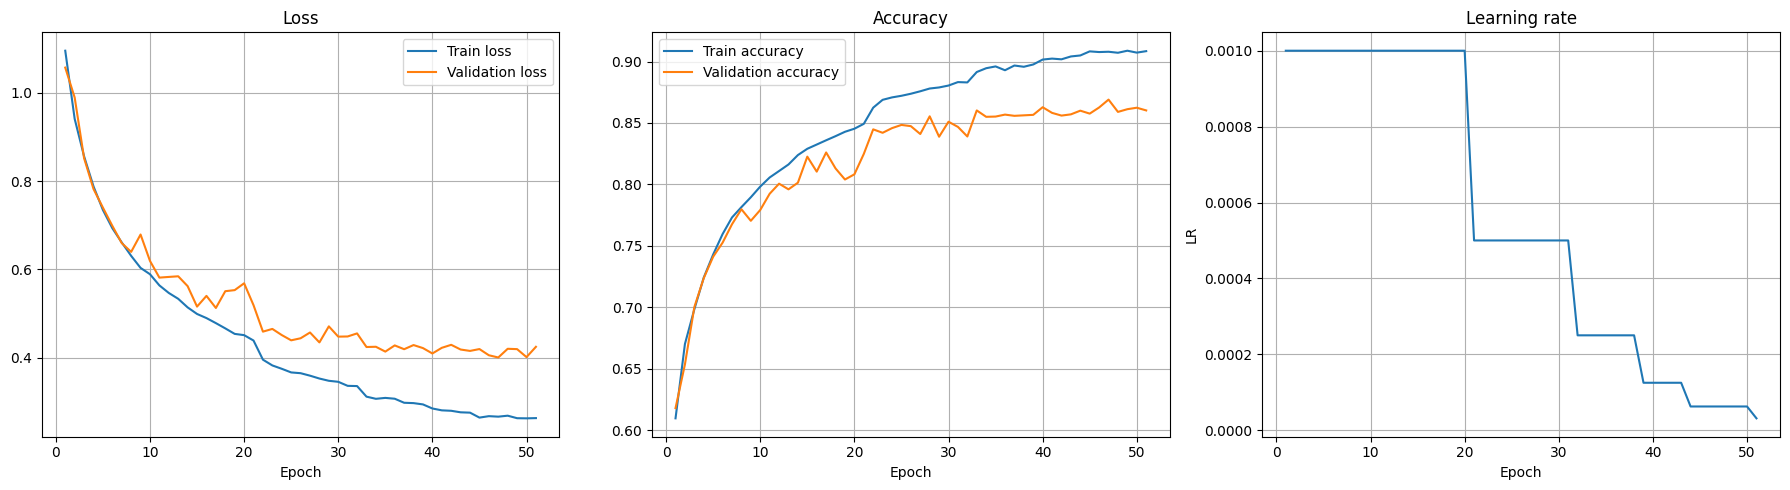

In [51]:
import matplotlib.pyplot as plt
epoch_numbers = range(
    1,
    len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

axes[0].plot(
    epoch_numbers,
    history["train_loss"],
    label="Train loss"
)

axes[0].plot(
    epoch_numbers,
    history["val_loss"],
    label="Validation loss"
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epoch_numbers,
    history["train_accuracy"],
    label="Train accuracy"
)

axes[1].plot(
    epoch_numbers,
    history["val_accuracy"],
    label="Validation accuracy"
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(
    epoch_numbers,
    history["learning_rate"]
)

axes[2].set_title("Learning rate")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("LR")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [58]:
import pandas as pd
from sklearn.metrics import classification_report

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

report = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

report_df.to_csv(
    "cifar10_test_classification_report.csv",
    index=True
)

history_df = pd.DataFrame(history)

history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_df.to_csv(
    "cifar10_training_history.csv"
)

history_df.head()

,train_loss,val_loss,train_accuracy,val_accuracy,learning_rate
epoch,,,,,
1,1.095043,1.056808,0.609689,0.6180,0.001
2,0.940850,0.989166,0.670222,0.6536,0.001
3,0.856145,0.851968,0.698444,0.7002,0.001
4,0.788139,0.782207,0.724222,0.7238,0.001
5,0.734697,0.740026,0.743000,0.7412,0.001
